# Prediksi Tingkat Risiko Kesehatan Ibu Hamil Menggunakan Algoritma K-Nearest Neighbors (KNN)

**Pipeline Kode**
1. Import Library & Load Dataset
2. Audit Kualitas Data (Anomali, Duplikat, dan Konflik Label)
3. Data Cleaning
4. Stratified Train-Test Split (80:20) # Inisialisasi Awal
5. Eksperimen Baseline KNN (Tanpa dan Dengan Scalling)
6. Hyperparameter Tuning Berorientasi Recall
7. Optimasi Threshold Khusus Kelas High Risk & Confusion Matrix
8. Simulasi Data Pasien Baru

**Field yang Digunakan**
| Kolom | Deskripsi |
|---|---|
| Age | Usia ibu (tahun) |
| SystolicBP | Tekanan darah sistolik (mmHg) |
| DiastolicBP | Tekanan darah diastolik (mmHg) |
| BS | Kadar gula darah (mmol/L) |
| BodyTemp | Suhu tubuh (°F) |
| HeartRate | Detak jantung (bpm) |
| RiskLevel | Tingkat risiko (low risk, mid risk, high risk) |

---
## 1. Import Library & Load Dataset

### 1.1 Import Library

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
sns.set_style('whitegrid')

import warnings
warnings.filterwarnings('ignore')

print('Library berhasil di-import!')

Library berhasil di-import!


### 1.2 Load Dataset

In [55]:
# Membaca dataset
df = pd.read_csv('Maternal Health Risk Data Set.csv')
print(f'Dataset berhasil dimuat! Ukuran: {df.shape[0]} baris x {df.shape[1]} kolom')

Dataset berhasil dimuat! Ukuran: 1014 baris x 7 kolom


### 1.3 Menampilkan Data Teratas & Terbawah

In [56]:
# 5 data teratas
df.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [57]:
# 5 data terbawah
df.tail()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
1009,22,120,60,15.0,98.0,80,high risk
1010,55,120,90,18.0,98.0,60,high risk
1011,35,85,60,19.0,98.0,86,high risk
1012,43,120,90,18.0,98.0,70,high risk
1013,32,120,65,6.0,101.0,76,mid risk


### 1.4 Informasi Dataset

In [58]:
# Info tipe data dan non-null count
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   str    
dtypes: float64(2), int64(4), str(1)
memory usage: 55.6 KB


In [59]:
# Dimensi dataset
print(f'Jumlah baris  : {df.shape[0]}')
print(f'Jumlah kolom  : {df.shape[1]}')
print(f'Nama kolom    : {list(df.columns)}')

Jumlah baris  : 1014
Jumlah kolom  : 7
Nama kolom    : ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']


### 1.5 Statistik Deskriptif

In [60]:
# Statistik deskriptif untuk kolom numerik
df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


In [61]:
# Statistik deskriptif untuk kolom kategorikal
df.describe(include='object')

,RiskLevel
count,1014
unique,3
top,low risk
freq,406


### 1.6 Distribusi Target (RiskLevel)

In [62]:
# Distribusi kelas target
print('Distribusi RiskLevel:')
print(df['RiskLevel'].value_counts())
print()
print('Persentase:')
print(df['RiskLevel'].value_counts(normalize=True).round(4) * 100)

Distribusi RiskLevel:
RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

Persentase:
RiskLevel
low risk     40.04
mid risk     33.14
high risk    26.82
Name: proportion, dtype: float64


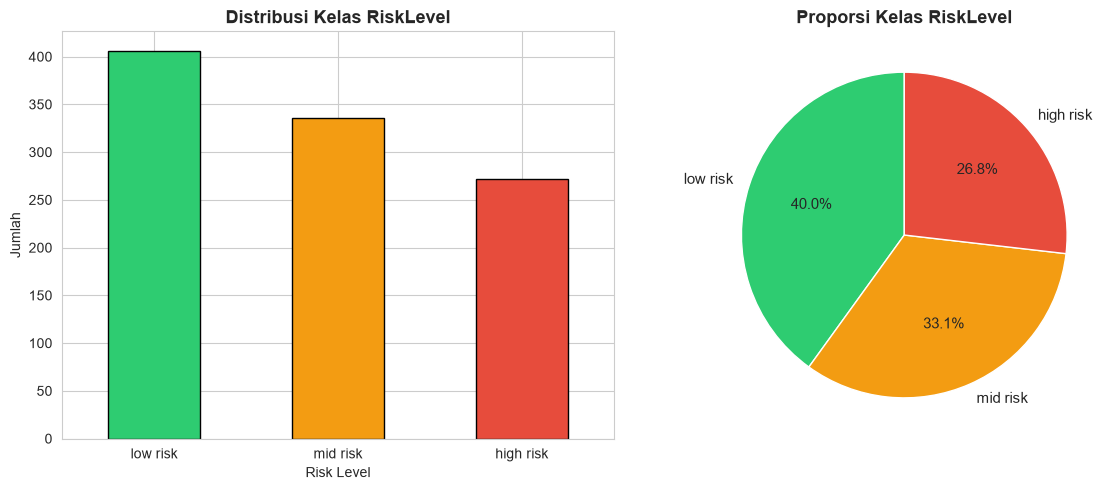

In [63]:
# Visualisasi distribusi target
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot
colors = ['#2ecc71', '#f39c12', '#e74c3c']
order = ['low risk', 'mid risk', 'high risk']
df['RiskLevel'].value_counts().reindex(order).plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Distribusi Kelas RiskLevel', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

# Pie chart
df['RiskLevel'].value_counts().reindex(order).plot(kind='pie', ax=axes[1], colors=colors,
    autopct='%1.1f%%', startangle=90, textprops={'fontsize': 11})
axes[1].set_title('Proporsi Kelas RiskLevel', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

---
## 2. Audit Kualitas Data (Anomali, Duplikat, dan Konflik Label)

### 2.1 Cek Missing Values

In [64]:
# Cek jumlah missing values per kolom
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Persentase (%)': missing_pct.round(2)
})
print(missing_df)
print(f'\nTotal missing values: {df.isnull().sum().sum()}')

             Missing Values  Persentase (%)
Age                       0             0.0
SystolicBP                0             0.0
DiastolicBP               0             0.0
BS                        0             0.0
BodyTemp                  0             0.0
HeartRate                 0             0.0
RiskLevel                 0             0.0

Total missing values: 0


### 2.2 Cek Data Duplikat (Exact Duplicates)

In [65]:
# Cek jumlah baris duplikat (semua kolom identik)
jumlah_duplikat = df.duplicated().sum()
print(f'Jumlah baris duplikat EXACT  : {jumlah_duplikat}')
print(f'Persentase duplikat          : {(jumlah_duplikat / len(df) * 100):.2f}%')

Jumlah baris duplikat EXACT  : 562
Persentase duplikat          : 55.42%


In [66]:
# Menampilkan beberapa contoh baris duplikat (jika ada)
if jumlah_duplikat > 0:
    print('Contoh baris duplikat (10 pertama):')
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10))

Contoh baris duplikat (10 pertama):


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
670,10,100,50,6.0,99.0,70,mid risk
849,10,100,50,6.0,99.0,70,mid risk
552,12,90,60,7.5,102.0,60,low risk
940,12,90,60,7.5,102.0,60,low risk
543,12,90,60,7.5,102.0,66,low risk
934,12,90,60,7.5,102.0,66,low risk
588,12,90,60,7.5,102.0,66,mid risk
827,12,90,60,7.5,102.0,66,mid risk
171,12,90,60,7.9,102.0,66,high risk
963,12,90,60,7.9,102.0,66,high risk


### 2.3 Cek Konflik Label

Konflik label terjadi ketika dua baris memiliki **fitur identik** tetapi **label (RiskLevel) berbeda**.  
Ini merupakan masalah serius karena model tidak dapat mempelajari pola yang konsisten dari data yang saling bertentangan.

In [67]:
# Kolom fitur (tanpa target)
feature_cols = ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']

# Cari kombinasi fitur yang memiliki lebih dari satu label unik
konflik = df.groupby(feature_cols)['RiskLevel'].nunique().reset_index()
konflik = konflik[konflik['RiskLevel'] > 1]
print(f'Jumlah kombinasi fitur dengan konflik label: {len(konflik)}')
print()

if len(konflik) > 0:
    # Tampilkan detail konflik
    print('Detail konflik label:')
    for _, row in konflik.iterrows():
        mask = (df[feature_cols] == row[feature_cols]).all(axis=1)
        subset = df[mask]
        print(f'\n--- Kombinasi fitur (muncul {len(subset)}x) ---')
        display(subset)
        print(f'  Label: {list(subset["RiskLevel"].unique())}')

Jumlah kombinasi fitur dengan konflik label: 35

Detail konflik label:

--- Kombinasi fitur (muncul 4x) ---


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
543,12,90,60,7.5,102.0,66,low risk
588,12,90,60,7.5,102.0,66,mid risk
827,12,90,60,7.5,102.0,66,mid risk
934,12,90,60,7.5,102.0,66,low risk


  Label: ['low risk', 'mid risk']

--- Kombinasi fitur (muncul 4x) ---


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
82,12,95,60,6.9,98.0,65,mid risk
251,12,95,60,6.9,98.0,65,low risk
351,12,95,60,6.9,98.0,65,mid risk
763,12,95,60,6.9,98.0,65,mid risk


  Label: ['mid risk', 'low risk']

--- Kombinasi fitur (muncul 3x) ---


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
561,13,90,65,7.5,101.0,80,low risk
610,13,90,65,7.5,101.0,80,high risk
946,13,90,65,7.5,101.0,80,low risk


... (61 outputs left out)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
556,60,120,80,7.5,98.0,75,low risk
601,60,120,80,7.5,98.0,75,mid risk
832,60,120,80,7.5,98.0,75,mid risk
941,60,120,80,7.5,98.0,75,low risk


  Label: ['low risk', 'mid risk']

--- Kombinasi fitur (muncul 9x) ---


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
91,60,120,85,15.0,98.0,60,mid risk
181,60,120,85,15.0,98.0,60,high risk
277,60,120,85,15.0,98.0,60,high risk
372,60,120,85,15.0,98.0,60,mid risk
553,60,120,85,15.0,98.0,60,mid risk
772,60,120,85,15.0,98.0,60,mid risk
818,60,120,85,15.0,98.0,60,mid risk
967,60,120,85,15.0,98.0,60,high risk
1001,60,120,85,15.0,98.0,60,high risk


  Label: ['mid risk', 'high risk']


In [68]:
# Hitung total baris yang terlibat konflik label
total_baris_konflik = 0
for _, row in konflik.iterrows():
    mask = (df[feature_cols] == row[feature_cols]).all(axis=1)
    total_baris_konflik += mask.sum()

print(f'Total baris yang terlibat konflik label: {total_baris_konflik}')
print(f'Persentase dari dataset: {(total_baris_konflik / len(df) * 100):.2f}%')

Total baris yang terlibat konflik label: 215
Persentase dari dataset: 21.20%


### 2.4 Deteksi Anomali / Outlier

In [69]:
# Cek tipe data setiap kolom
print('Tipe data:')
print(df.dtypes)
print()

# Cek nilai unik per kolom
print('Nilai unik per kolom:')
for col in df.columns:
    print(f'  {col:15s} | Unik: {df[col].nunique():5d} | Min: {df[col].min()} | Max: {df[col].max()}')

Tipe data:
Age              int64
SystolicBP       int64
DiastolicBP      int64
BS             float64
BodyTemp       float64
HeartRate        int64
RiskLevel          str
dtype: object

Nilai unik per kolom:
  Age             | Unik:    50 | Min: 10 | Max: 70
  SystolicBP      | Unik:    19 | Min: 70 | Max: 160
  DiastolicBP     | Unik:    16 | Min: 49 | Max: 100
  BS              | Unik:    29 | Min: 6.0 | Max: 19.0
  BodyTemp        | Unik:     8 | Min: 98.0 | Max: 103.0
  HeartRate       | Unik:    16 | Min: 7 | Max: 90
  RiskLevel       | Unik:     3 | Min: high risk | Max: mid risk


In [70]:
# Deteksi anomali berdasarkan domain knowledge medis
print('=== Deteksi Anomali berdasarkan Domain Knowledge ===')
print()

# HeartRate = 7 bpm (tidak masuk akal secara medis, normal: 60-100 bpm)
anomali_hr = df[df['HeartRate'] < 40]
print(f'HeartRate < 40 bpm (tidak wajar): {len(anomali_hr)} baris')
if len(anomali_hr) > 0:
    display(anomali_hr)
print()

# Age < 13 atau Age > 60 (rentang usia hamil yang tidak umum)
anomali_age_low = df[df['Age'] < 13]
anomali_age_high = df[df['Age'] > 60]
print(f'Age < 13 tahun (tidak umum untuk kehamilan): {len(anomali_age_low)} baris')
print(f'Age > 60 tahun (tidak umum untuk kehamilan): {len(anomali_age_high)} baris')
print()

=== Deteksi Anomali berdasarkan Domain Knowledge ===

HeartRate < 40 bpm (tidak wajar): 2 baris


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
499,16,120,75,7.9,98.0,7,low risk
908,16,120,75,7.9,98.0,7,low risk



Age < 13 tahun (tidak umum untuk kehamilan): 39 baris
Age > 60 tahun (tidak umum untuk kehamilan): 8 baris



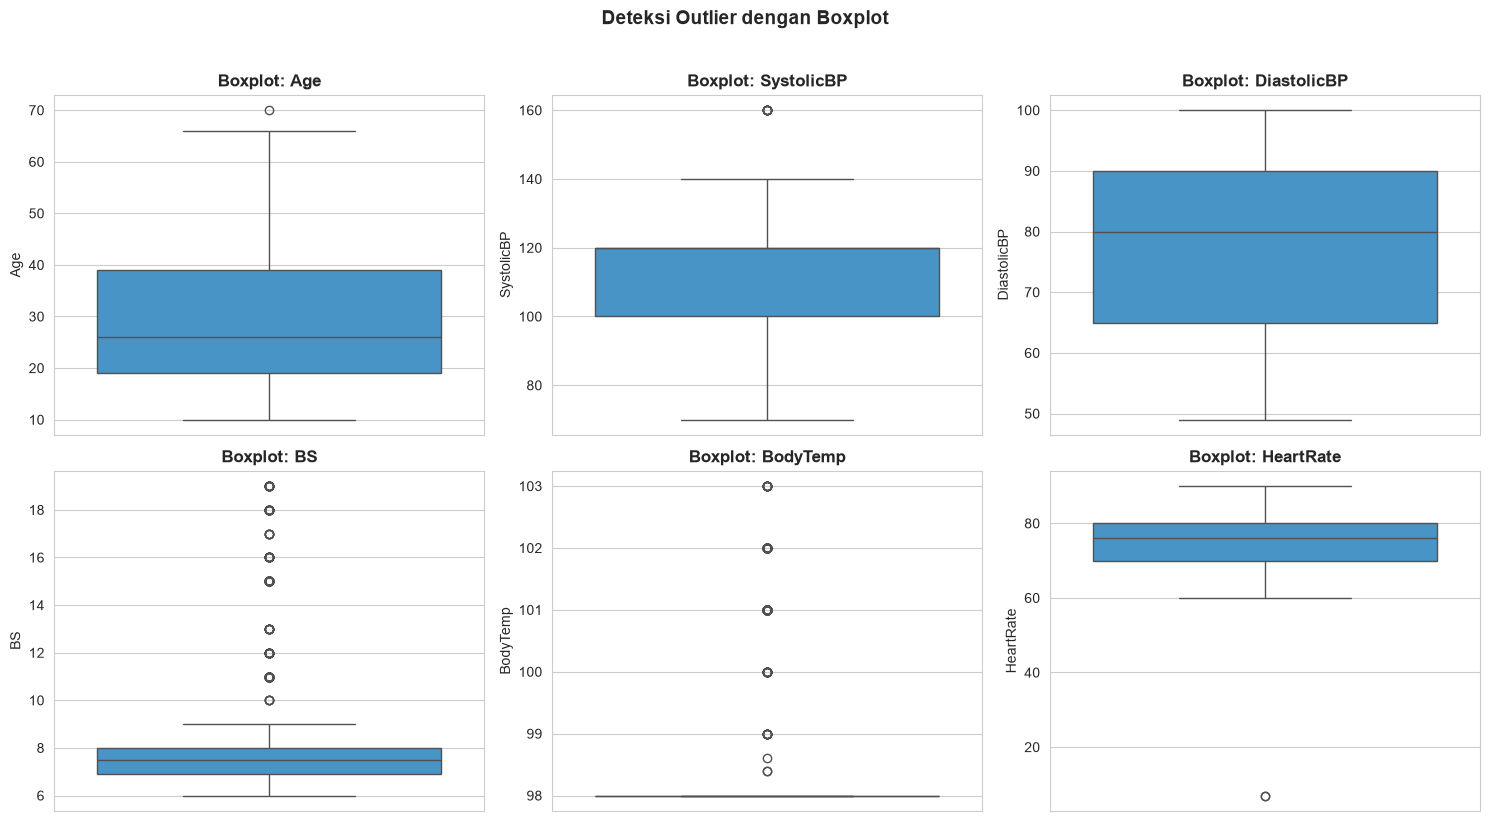

In [71]:
# Boxplot untuk semua fitur numerik
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color='#3498db')
    axes[i].set_title(f'Boxplot: {col}', fontsize=12, fontweight='bold')

plt.suptitle('Deteksi Outlier dengan Boxplot', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [72]:
# Deteksi outlier menggunakan metode IQR
print('=== Deteksi Outlier (Metode IQR) ===')
print()

outlier_summary = []
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    pct = len(outliers) / len(df) * 100
    print(f'{col:15s} | Batas: [{lower:.2f}, {upper:.2f}] | Outlier: {len(outliers)} ({pct:.1f}%)')
    outlier_summary.append({'Kolom': col, 'Jumlah_Outlier': len(outliers), 'Persen': pct})

=== Deteksi Outlier (Metode IQR) ===

Age             | Batas: [-11.00, 69.00] | Outlier: 1 (0.1%)
SystolicBP      | Batas: [70.00, 150.00] | Outlier: 10 (1.0%)
DiastolicBP     | Batas: [27.50, 127.50] | Outlier: 0 (0.0%)
BS              | Batas: [5.25, 9.65] | Outlier: 210 (20.7%)
BodyTemp        | Batas: [98.00, 98.00] | Outlier: 210 (20.7%)
HeartRate       | Batas: [55.00, 95.00] | Outlier: 2 (0.2%)


### 2.5 Ringkasan Temuan Audit

Sebelum melanjutkan ke Data Cleaning, berikut rangkuman masalah yang ditemukan:

In [73]:
print('=' * 65)
print('           RINGKASAN AUDIT KUALITAS DATA')
print('=' * 65)
print(f'  Total baris awal                : {len(df)}')
print(f'  Missing values                  : {df.isnull().sum().sum()}')
print(f'  Exact duplicates                : {jumlah_duplikat}')
print(f'  Konflik label (kombinasi fitur) : {len(konflik)}')
print(f'  Baris terlibat konflik label    : {total_baris_konflik}')
print(f'  Anomali HeartRate < 40          : {len(anomali_hr)}')
print(f'  Age < 13 tahun                  : {len(anomali_age_low)}')
print(f'  Age > 60 tahun                  : {len(anomali_age_high)}')
print('=' * 65)

           RINGKASAN AUDIT KUALITAS DATA
  Total baris awal                : 1014
  Missing values                  : 0
  Exact duplicates                : 562
  Konflik label (kombinasi fitur) : 35
  Baris terlibat konflik label    : 215
  Anomali HeartRate < 40          : 2
  Age < 13 tahun                  : 39
  Age > 60 tahun                  : 8


---
## 3. Data Cleaning

Berdasarkan hasil audit di atas, berikut langkah-langkah cleaning yang dilakukan:

1. **Hapus anomali HeartRate** (nilai < 40 bpm yang secara medis tidak valid)
2. **Hapus baris dengan konflik label** (fitur identik tetapi label berbeda — ambigu untuk model)
3. **Hapus exact duplicates** (baris yang 100% identik)
4. **Verifikasi hasil akhir**

### 3.1 Hapus Anomali HeartRate

In [74]:
print(f'Jumlah baris SEBELUM hapus anomali HeartRate: {len(df)}')

# Hapus baris dengan HeartRate < 40 (tidak valid secara medis)
df_clean = df[df['HeartRate'] >= 40].copy()

print(f'Jumlah baris SETELAH hapus anomali HeartRate : {len(df_clean)}')
print(f'Baris dihapus: {len(df) - len(df_clean)}')

Jumlah baris SEBELUM hapus anomali HeartRate: 1014
Jumlah baris SETELAH hapus anomali HeartRate : 1012
Baris dihapus: 2


### 3.2 Hapus Baris dengan Konflik Label

In [75]:
print(f'Jumlah baris SEBELUM hapus konflik label: {len(df_clean)}')

# Identifikasi kombinasi fitur yang memiliki konflik label
konflik_clean = df_clean.groupby(feature_cols)['RiskLevel'].nunique().reset_index()
konflik_clean = konflik_clean[konflik_clean['RiskLevel'] > 1]

# Buat mask untuk baris-baris yang terlibat konflik
mask_konflik = pd.Series([False] * len(df_clean), index=df_clean.index)
for _, row in konflik_clean.iterrows():
    cond = (df_clean[feature_cols] == row[feature_cols]).all(axis=1)
    mask_konflik = mask_konflik | cond

# Hapus baris konflik
df_clean = df_clean[~mask_konflik].copy()

print(f'Jumlah baris SETELAH hapus konflik label : {len(df_clean)}')
print(f'Baris dihapus: {mask_konflik.sum()}')

Jumlah baris SEBELUM hapus konflik label: 1012
Jumlah baris SETELAH hapus konflik label : 797
Baris dihapus: 215


### 3.3 Hapus Exact Duplicates

In [76]:
print(f'Jumlah baris SEBELUM hapus duplikat: {len(df_clean)}')

# Hapus duplikat (pertahankan kemunculan pertama)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f'Jumlah baris SETELAH hapus duplikat : {len(df_clean)}')

Jumlah baris SEBELUM hapus duplikat: 797
Jumlah baris SETELAH hapus duplikat : 380


### 3.4 Verifikasi Hasil Cleaning

In [77]:
print('=== VERIFIKASI DATA SETELAH CLEANING ===')
print()
print(f'Dimensi data bersih       : {df_clean.shape}')
print(f'Missing values            : {df_clean.isnull().sum().sum()}')
print(f'Exact duplicates tersisa  : {df_clean.duplicated().sum()}')

# Verifikasi konflik label sudah hilang
konflik_verify = df_clean.groupby(feature_cols)['RiskLevel'].nunique().reset_index()
konflik_verify = konflik_verify[konflik_verify['RiskLevel'] > 1]
print(f'Konflik label tersisa     : {len(konflik_verify)}')

# Verifikasi anomali HeartRate sudah hilang
print(f'HeartRate < 40 tersisa    : {len(df_clean[df_clean["HeartRate"] < 40])}')
print()

# Info dataset bersih
df_clean.info()

=== VERIFIKASI DATA SETELAH CLEANING ===

Dimensi data bersih       : (380, 7)
Missing values            : 0
Exact duplicates tersisa  : 0
Konflik label tersisa     : 0
HeartRate < 40 tersisa    : 0

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          380 non-null    int64  
 1   SystolicBP   380 non-null    int64  
 2   DiastolicBP  380 non-null    int64  
 3   BS           380 non-null    float64
 4   BodyTemp     380 non-null    float64
 5   HeartRate    380 non-null    int64  
 6   RiskLevel    380 non-null    str    
dtypes: float64(2), int64(4), str(1)
memory usage: 20.9 KB


In [78]:
# Statistik deskriptif data bersih
df_clean.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000
mean,29.273684,110.657895,75.115789,8.371500,98.739474,73.947368
std,13.754302,18.544073,13.961208,2.852294,1.429733,7.530579
min,10.000000,70.000000,49.000000,6.000000,98.000000,60.000000
25%,19.000000,90.000000,65.000000,6.900000,98.000000,70.000000
50%,25.000000,120.000000,75.500000,7.500000,98.000000,76.000000
75%,35.000000,120.000000,86.000000,7.900000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


Distribusi RiskLevel setelah cleaning:
RiskLevel
low risk     203
high risk    101
mid risk      76
Name: count, dtype: int64

Persentase:
RiskLevel
low risk     53.42
high risk    26.58
mid risk     20.00
Name: proportion, dtype: float64



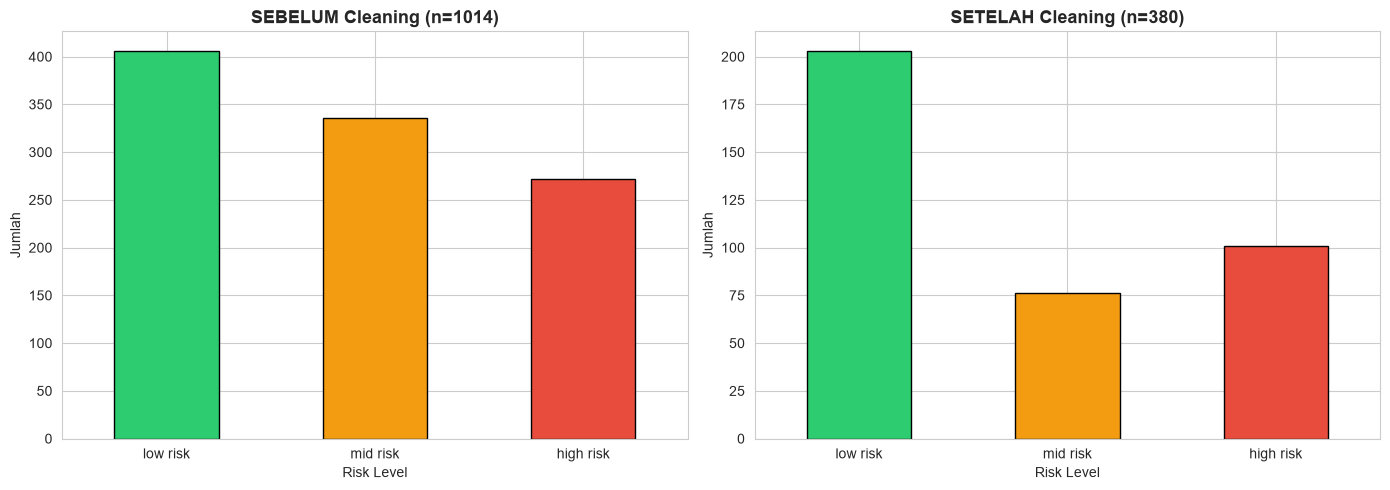

In [79]:
# Distribusi target setelah cleaning
print('Distribusi RiskLevel setelah cleaning:')
print(df_clean['RiskLevel'].value_counts())
print()
print('Persentase:')
print(df_clean['RiskLevel'].value_counts(normalize=True).round(4) * 100)
print()

# Visualisasi perbandingan distribusi sebelum vs sesudah cleaning
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#2ecc71', '#f39c12', '#e74c3c']
order = ['low risk', 'mid risk', 'high risk']

# Sebelum cleaning
df['RiskLevel'].value_counts().reindex(order).plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title(f'SEBELUM Cleaning (n={len(df)})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

# Setelah cleaning
df_clean['RiskLevel'].value_counts().reindex(order).plot(kind='bar', ax=axes[1], color=colors, edgecolor='black')
axes[1].set_title(f'SETELAH Cleaning (n={len(df_clean)})', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Risk Level')
axes[1].set_ylabel('Jumlah')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### 3.5 Visualisasi Data Bersih

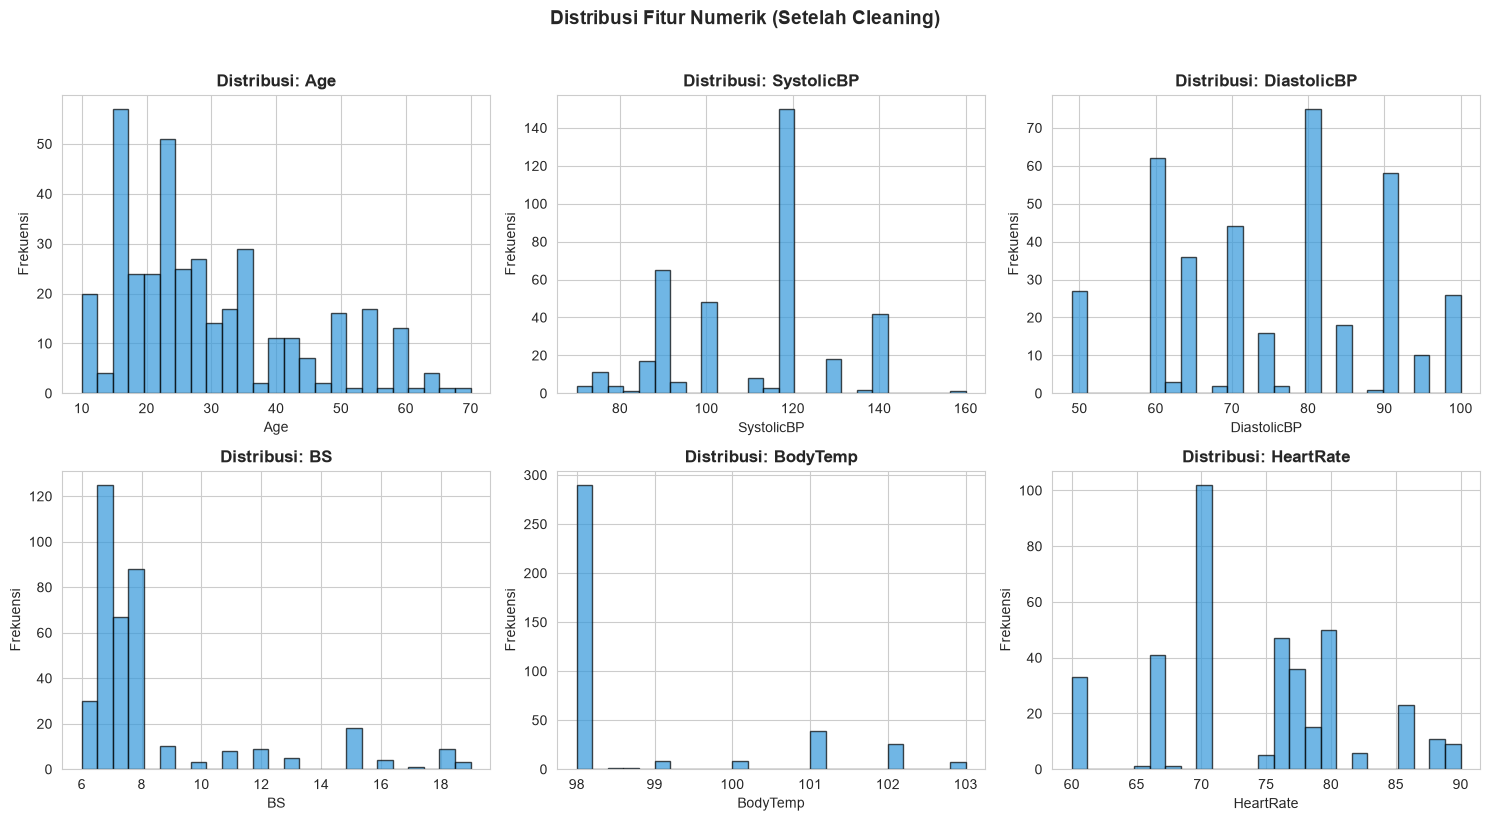

In [80]:
# Histogram distribusi setiap fitur numerik setelah cleaning
numerical_cols_clean = df_clean.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols_clean):
    df_clean[col].hist(bins=25, ax=axes[i], color='#3498db', edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribusi: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

plt.suptitle('Distribusi Fitur Numerik (Setelah Cleaning)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

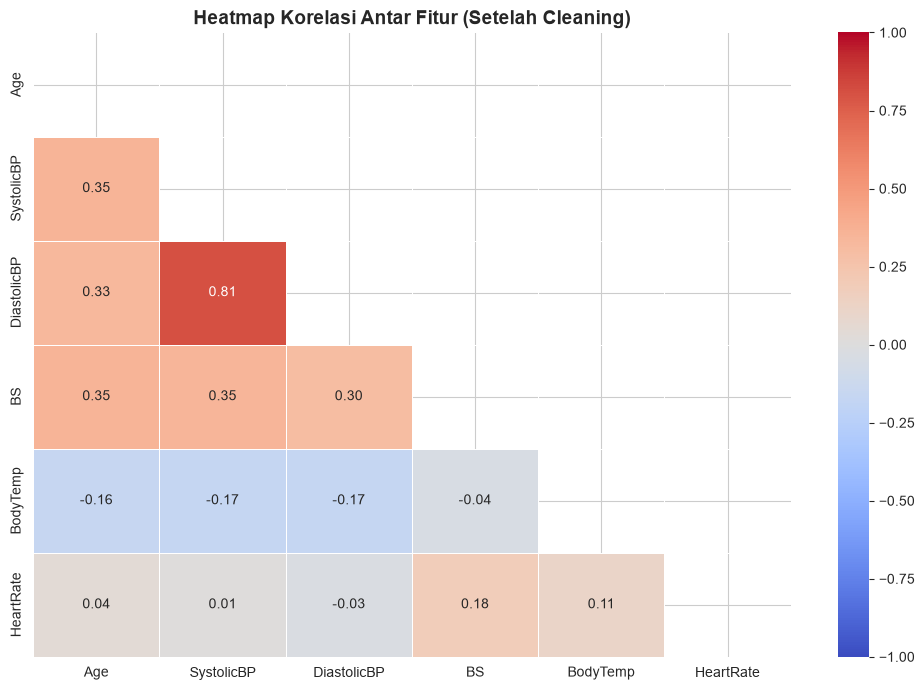

In [81]:
# Heatmap korelasi data bersih
plt.figure(figsize=(10, 7))
corr_matrix = df_clean[numerical_cols_clean].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=mask,
            linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title('Heatmap Korelasi Antar Fitur (Setelah Cleaning)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.6 Ringkasan Cleaning

Data telah dibersihkan dan siap untuk tahap selanjutnya (**Poin 4: Stratified Train-Test Split**).

In [82]:
print('=' * 65)
print('          RINGKASAN PROSES DATA CLEANING')
print('=' * 65)
print(f'  Baris awal (raw)                     : {len(df)}')
print(f'  Baris dihapus (anomali HeartRate)     : {len(df[df["HeartRate"] < 40])}')
print(f'  Baris dihapus (konflik label)         : {total_baris_konflik}')
print(f'  Baris dihapus (exact duplicate)       : (sisa duplikat dari langkah sebelumnya)')
print(f'  Baris akhir (clean)                   : {len(df_clean)}')
print(f'  Persen data dipertahankan             : {(len(df_clean) / len(df) * 100):.1f}%')
print('=' * 65)
print()
print('Data bersih tersedia di variabel: df_clean')

          RINGKASAN PROSES DATA CLEANING
  Baris awal (raw)                     : 1014
  Baris dihapus (anomali HeartRate)     : 2
  Baris dihapus (konflik label)         : 215
  Baris dihapus (exact duplicate)       : (sisa duplikat dari langkah sebelumnya)
  Baris akhir (clean)                   : 380
  Persen data dipertahankan             : 37.5%

Data bersih tersedia di variabel: df_clean


In [83]:
# Simpan data yang sudah bersih (opsional)
# df_clean.to_csv('Maternal_Health_Clean.csv', index=False)
# print('Data bersih berhasil disimpan ke: Maternal_Health_Clean.csv')